# A café: counting people in a queue

Not every simulation is a signal. Here the samples are seconds and the
values are people: customers arrive at random, wait, are served by one of a
few baristas, or leave when the queue is too long. Random sources decide
who arrives and who is done; one `FuncSingle` with named state keeps the
count in whole people. The day is a sequence of runs with different arrival
rates, and the staffing question is a `for` loop. A long run with one
barista is checked against the exact distribution of a Markov chain.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import sigline as sl

fs = 1.0  # one step per second

## 1. The model

Each second:

1. every busy barista finishes with probability $\mu$ (mean service time
   $1/\mu$ seconds): a `RandomPulses` per barista;
2. a customer arrives with probability $\lambda / 3600$ for $\lambda$
   customers per hour: another `RandomPulses`;
3. if ten people already wait, the newcomer leaves (is lost);
4. free baristas take the next people in the queue.

The shop is a function of one second, written with `if` and integers. Its
state counts people: waiting, being served, served so far, lost so far.

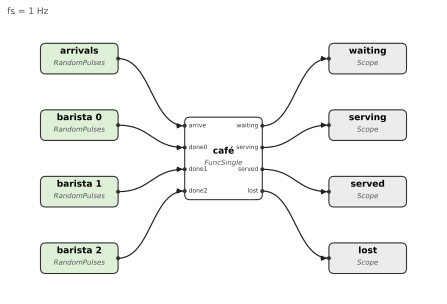

In [2]:
def cafe(arrive, done0, done1, done2, s, baristas=2, max_waiting=10):
    # one second in the café; s counts people
    waiting, serving, served, lost = s.waiting, s.serving, s.served, s.lost
    finished = 0
    for k, done in enumerate((done0, done1, done2)):
        if k < serving and done > 0:
            finished += 1
    serving -= finished
    served += finished
    if arrive > 0:
        if waiting < max_waiting:
            waiting += 1
        else:
            lost += 1
    while serving < baristas and waiting > 0:
        serving += 1
        waiting -= 1
    s = type(s)(waiting, serving, served, lost)
    return (waiting, serving, served, lost), s


def build(baristas, rate_per_hour, service_s=120.0, max_waiting=10, seed=1):
    arrivals = sl.RandomPulses(p=rate_per_hour / 3600, seed=seed, name="arrivals")
    shop = sl.FuncSingle(
        cafe,
        state=sl.state(waiting=0, serving=0, served=0, lost=0),
        outputs=("waiting", "serving", "served", "lost"),
        params={"baristas": baristas, "max_waiting": max_waiting},
        name="café",
    )
    arrivals >> shop["arrive"]
    for k in range(3):
        (
            sl.RandomPulses(p=1 / service_s, seed=seed + 10 + k, name=f"barista {k}")
            >> shop[f"done{k}"]
        )
    scopes = {k: sl.Scope(k) for k in shop.outputs}
    for k, sc in scopes.items():
        shop[k] >> sc
    return sl.Diagram(*scopes.values(), fs=fs), arrivals, shop, scopes


d, arrivals, shop, scopes = build(2, 40.0)
d

## 2. Checked against theory: one barista

With one barista and no limit, the number of people in the café, $n$, is a
Markov chain. From $n \ge 1$ a departure happens with probability $q = \mu$,
an arrival with $p = \lambda/3600$, independently: $n$ goes down with
$q(1-p)$, up with $p(1-q)$, and stays otherwise. From 0 it goes up with
$p$. `MarkovChain(P).stationary()` gives the long-run distribution; thirty
simulated days at 20 customers per hour and two minutes per coffee should
match it within the statistical error. That error is large for a queue:
one busy hour lasts many seconds, so 2.6 million seconds hold far fewer
independent samples.

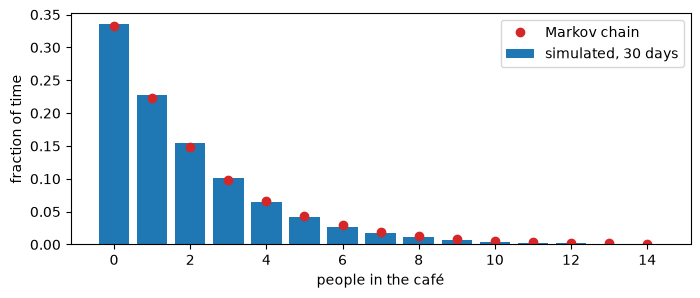

mean people: simulated 1.896 ± 0.074, theory 1.989
mean time in the café (Little: L / lambda): 5.97 min
served 14482 of about 14400 arrivals


In [3]:
p, q = 20 / 3600, 1 / 120
N = 80  # enough states: the tail beyond is negligible
P = np.zeros((N, N))
P[0, 0], P[0, 1] = 1 - p, p
for n in range(1, N - 1):
    P[n, n - 1], P[n, n + 1] = q * (1 - p), p * (1 - q)
    P[n, n] = 1 - P[n, n - 1] - P[n, n + 1]
P[N - 1, N - 2], P[N - 1, N - 1] = q * (1 - p), 1 - q * (1 - p)
pi = sl.MarkovChain(P).stationary()

d, arrivals, shop, scopes = build(1, 20.0, max_waiting=10**6, seed=7)
d.run(30 * 24 * 3600, chunk=86400)
people = scopes["waiting"].data + scopes["serving"].data
counts = np.bincount(people.astype(int), minlength=N)[:N] / len(people)

n = np.arange(15)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(n, counts[:15], label="simulated, 30 days")
ax.plot(n, pi[:15], "o", c="C3", label="Markov chain")
ax.set(xlabel="people in the café", ylabel="fraction of time")
ax.legend()
plt.show()

L = np.sum(np.arange(N) * pi)
# successive seconds are strongly correlated: the error of the mean comes
# from the spread of the 30 daily means
daily = people.reshape(30, -1).mean(axis=1)
se = daily.std(ddof=1) / np.sqrt(30)
print(f"mean people: simulated {people.mean():.3f} ± {se:.3f}, theory {L:.3f}")
print(f"mean time in the café (Little: L / lambda): {L / p / 60:.2f} min")
print(f"served {scopes['served'].data[-1]:.0f} of about {30 * 24 * 20} arrivals")

## 3. A day in the café

Arrivals follow the day: a breakfast rush, a quiet morning, lunch, a quiet
afternoon. Each period is one more `run`: the arrival probability changes
between runs, everything else continues.

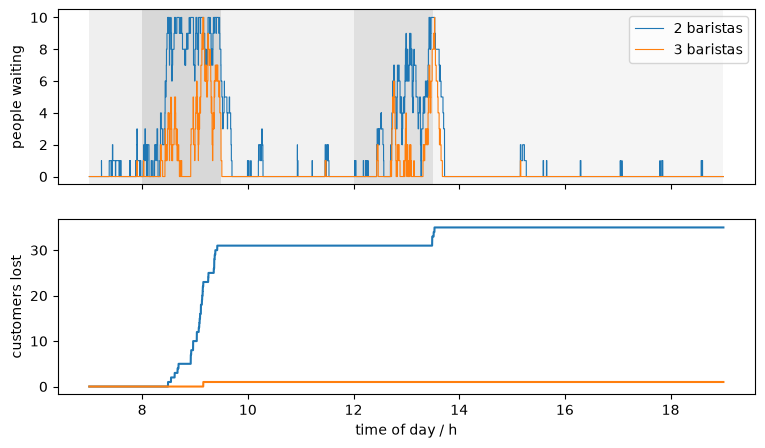

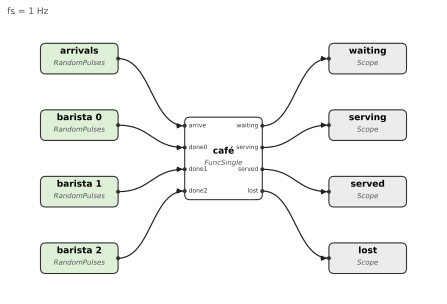

In [4]:
day = [  # (from, to) / h, customers per hour
    ((7.0, 8.0), 30.0),
    ((8.0, 9.5), 75.0),
    ((9.5, 12.0), 25.0),
    ((12.0, 13.5), 60.0),
    ((13.5, 19.0), 20.0),
]


def run_day(baristas, seed=1):
    d, arrivals, shop, scopes = build(baristas, 0.0, seed=seed)
    for (start, end), rate in day:
        arrivals.p_start = rate / 3600
        d.run((end - start) * 3600, chunk=900)
    return d, scopes


fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
results = {}
for baristas in (2, 3):
    d, scopes = run_day(baristas)
    hours = 7 + d.t / 3600
    axes[0].step(
        hours,
        scopes["waiting"].data,
        where="post",
        lw=0.8,
        label=f"{baristas} baristas",
    )
    axes[1].plot(hours, scopes["lost"].data, label=f"{baristas} baristas")
    results[baristas] = scopes
for (start, end), rate in day:
    axes[0].axvspan(start, end, alpha=0.08 * rate / 20, color="gray", lw=0)
axes[0].set(ylabel="people waiting")
axes[0].legend(loc="upper right")
axes[1].set(xlabel="time of day / h", ylabel="customers lost")
plt.show()
d

Two baristas serve 60 customers an hour at most; the breakfast rush brings
75. The queue fills, and newcomers who see ten people waiting leave. Both
runs see the same customers (the same seed). With a third barista the
rushes still fill the queue at times, but it drains within minutes and
hardly anyone leaves. Shading marks the arrival rate.

## 4. How many baristas?

The same day, many times with different random seeds, for one to three
baristas: a `for` loop over seeds inside a `for` loop over staff.

In [5]:
print("baristas   served   lost   mean waiting   time waiting / min")
for baristas in (1, 2, 3):
    served, lost, waiting = [], [], []
    for seed in range(20):
        d, scopes = run_day(baristas, seed=seed)
        served.append(scopes["served"].data[-1])
        lost.append(scopes["lost"].data[-1])
        waiting.append(scopes["waiting"].data.mean())
    # little's law: time waiting = people waiting / customers per second
    per_s = np.mean(served) / (12 * 3600)
    print(
        f"{baristas:8d}   {np.mean(served):6.0f}   {np.mean(lost):4.0f}   "
        f"{np.mean(waiting):12.2f}   {np.mean(waiting) / per_s / 60:17.1f}"
    )

baristas   served   lost   mean waiting   time waiting / min


       1      300    107           4.01                 9.6


       2      383     26           1.43                 2.7


       3      407      2           0.40                 0.7


## 5. Watching the rush

`d.watch` plays the simulation paced to the wall clock, here 900 times
faster: the 90 minutes of the breakfast rush in six seconds. Each dot is a
person; the queue builds up, the baristas work through it, and people turn
away while ten are waiting.

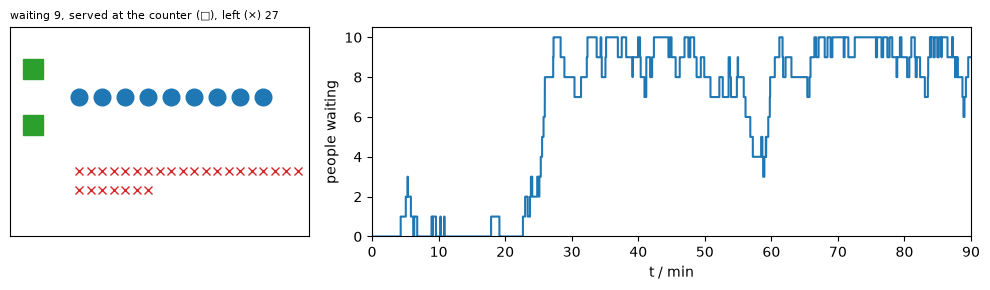

In [6]:
d, arrivals, shop, scopes = build(2, 75.0, seed=3)


def draw(fig):
    t, waiting = scopes["waiting"].snapshot()
    if not len(t):
        return
    serving, lost = scopes["serving"].data[-1], scopes["lost"].data[-1]
    a1, a2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 2]})
    a1.plot(np.arange(int(waiting[-1])), np.zeros(int(waiting[-1])), "o", ms=12, c="C0")
    a1.plot([-2, -2][: int(serving)], [0.6, -0.6][: int(serving)], "s", ms=14, c="C2")
    a1.plot(np.arange(int(lost)) % 20 * 0.5, -1.6 - np.arange(int(lost)) // 20 * 0.4,
            "x", c="C3")  # fmt: skip
    a1.set(xlim=(-3, 10), ylim=(-3, 1.5), xticks=[], yticks=[])
    a1.set_title(f"waiting {waiting[-1]:.0f}, served at the counter (□), "
                 f"left (×) {lost:.0f}", fontsize=8, loc="left")  # fmt: skip
    a2.step(t / 60, waiting, where="post")
    a2.set(xlim=(0, 90), ylim=(0, 10.5), xlabel="t / min", ylabel="people waiting")
    fig.tight_layout()


d.watch(1.5 * 3600, draw, speed=900, interval=0.15, figsize=(10, 3))

## Summary

- Discrete events fit the same blocks: random sources (`RandomPulses`) for
  arrivals and service, a `FuncSingle` with named integer state for the
  bookkeeping, one step per second.
- The simulation matches the exact stationary distribution of the Markov
  chain (`MarkovChain.stationary`).
- Schedules are runs with changed parameters; staffing is a `for` loop.
- `d.watch(T, draw, speed=900)` plays a simulation live, faster than real
  time.